# Credit Card Default Prediction - End-to-End ML Pipeline

This notebook covers the complete machine learning workflow:

1. Problem Definition  
2. Data Collection / Loading  
3. EDA  
4. Data Cleaning  
5. Missing Value Handling  
6. Visualization  
7. Feature Engineering  
8. Statistical Analysis  
9. Outlier Handling  
10. Imbalance Handling  
11. Scaling / Normalization  
12. Train / Validation / Test Split  
13. Baseline Model  
14. Model Training  
15. Cross Validation  
16. Hyperparameter Tuning  
17. Evaluation Metrics  
18. SHAP Explainability  
19. Error Analysis  
20. Model Saving / Deployment Ready


## 1. Problem Definition

**Goal:** Predict whether a credit card client will default on their next payment (binary classification).

**Target variable:** `default` (1 = default, 0 = no default)

**Dataset:** UCI Credit Card Default dataset (or equivalent). Contains demographic info, credit history, payment records, and bill amounts for 30,000 clients.

**Business Impact:** Identifying potential defaulters early allows the bank to:
- Proactively manage credit risk
- Reduce financial losses
- Offer targeted interventions to at-risk customers

**Success Metric:** ROC-AUC (primary), F1-score on the minority class (secondary). Accuracy alone is misleading due to class imbalance.

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
import os

from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr

from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV,
    cross_val_score, StratifiedKFold
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay, f1_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.utils import resample
from sklearn.inspection import permutation_importance

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP not installed. Run: pip install shap")

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All imports successful.")


SHAP not installed. Run: pip install shap
All imports successful.


## 2. Data Collection / Loading

Using the UCI Credit Card Default dataset. If the CSV is not present locally, we auto-download it via the UCI ML repository.

In [2]:
# ── Load Dataset ─────────────────────────────────────────────────────────────
# Option 1: Load from local file
DATA_PATH = 'notebook\data\raw.csv'

# Option 2: Auto-download from UCI (uncomment if needed)
# import urllib.request
# url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00350/default%20of%20credit%20card%20clients.xls'
# urllib.request.urlretrieve(url, 'credit_card_default.xls')
# df_raw = pd.read_excel('credit_card_default.xls', header=1)
# df_raw.to_csv(DATA_PATH, index=False)

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    # ── Synthetic fallback for demonstration ─────────────────────────────────
    print(f"'{DATA_PATH}' not found. Generating synthetic dataset for demonstration.")
    np.random.seed(RANDOM_STATE)
    n = 30000
    df = pd.DataFrame({
        'ID':            range(1, n + 1),
        'LIMIT_BAL':     np.random.choice([10000,20000,30000,50000,80000,100000,150000,200000,500000], n),
        'SEX':           np.random.choice([1, 2], n),
        'EDUCATION':     np.random.choice([0, 1, 2, 3, 4, 5, 6], n),
        'MARRIAGE':      np.random.choice([0, 1, 2, 3], n),
        'AGE':           np.random.randint(21, 75, n),
        'PAY_0':         np.random.choice(range(-2, 9), n),
        'PAY_2':         np.random.choice(range(-2, 9), n),
        'PAY_3':         np.random.choice(range(-2, 9), n),
        'PAY_4':         np.random.choice(range(-2, 9), n),
        'PAY_5':         np.random.choice(range(-2, 9), n),
        'PAY_6':         np.random.choice(range(-2, 9), n),
        'BILL_AMT1':     np.random.randint(-10000, 800000, n).astype(float),
        'BILL_AMT2':     np.random.randint(-10000, 800000, n).astype(float),
        'BILL_AMT3':     np.random.randint(-10000, 800000, n).astype(float),
        'BILL_AMT4':     np.random.randint(-10000, 800000, n).astype(float),
        'BILL_AMT5':     np.random.randint(-10000, 800000, n).astype(float),
        'BILL_AMT6':     np.random.randint(-10000, 800000, n).astype(float),
        'PAY_AMT1':      np.random.randint(0, 500000, n).astype(float),
        'PAY_AMT2':      np.random.randint(0, 500000, n).astype(float),
        'PAY_AMT3':      np.random.randint(0, 500000, n).astype(float),
        'PAY_AMT4':      np.random.randint(0, 500000, n).astype(float),
        'PAY_AMT5':      np.random.randint(0, 500000, n).astype(float),
        'PAY_AMT6':      np.random.randint(0, 500000, n).astype(float),
        'default':       np.random.choice([0, 1], n, p=[0.78, 0.22])
    })
    # Inject a few NaNs to test imputation
    for col in ['BILL_AMT1', 'PAY_AMT1', 'AGE', 'EDUCATION']:
        df.loc[np.random.choice(df.index, 300, replace=False), col] = np.nan

# Standardise target column name
if 'default payment next month' in df.columns:
    df.rename(columns={'default payment next month': 'default'}, inplace=True)

print(f"Dataset shape: {df.shape}")
df.head()


aw.csv' not found. Generating synthetic dataset for demonstration.
Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,150000,1,4.0000,1,31.0000,4,5,2,8,2,1,231069.0000,-7514.0000,362534.0000,785373.0000,417237.0000,425913.0000,450397.0000,226918.0000,317076.0000,93560.0000,63550.0000,425262.0000,1
1,2,50000,2,4.0000,3,53.0000,-1,3,5,4,3,6,14453.0000,787228.0000,592434.0000,319273.0000,691457.0000,528662.0000,344950.0000,140927.0000,211039.0000,143294.0000,24390.0000,205979.0000,1
2,3,200000,1,4.0000,2,26.0000,-1,0,8,8,7,-1,11192.0000,323053.0000,336461.0000,418193.0000,243629.0000,557599.0000,145170.0000,150607.0000,375101.0000,493648.0000,15387.0000,151588.0000,0
3,4,80000,1,3.0000,1,49.0000,8,5,2,3,7,-2,79418.0000,761311.0000,684865.0000,310636.0000,669265.0000,785204.0000,132738.0000,452366.0000,61087.0000,122322.0000,18157.0000,379614.0000,0
4,5,150000,1,4.0000,0,64.0000,5,-1,2,-1,4,7,673013.0000,499711.0000,568108.0000,288692.0000,523593.0000,38914.0000,135873.0000,492431.0000,161169.0000,195000.0000,280788.0000,88046.0000,1


## 3. EDA

In [3]:
# ── EDA ───────────────────────────────────────────────────────────────────────

print("=" * 60)
print("SHAPE & DTYPES")
print("=" * 60)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print()
print(df.dtypes)

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)
display(df.describe(include='all'))

print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)
print(missing_df if not missing_df.empty else "No missing values.")

print("\n" + "=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)
target_counts = df['default'].value_counts()
target_pct    = df['default'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': target_counts, 'Percentage %': target_pct.round(2)}))

print("\n" + "=" * 60)
print("DUPLICATE ROWS")
print("=" * 60)
print(f"Duplicate rows: {df.duplicated().sum()}")

print("\n" + "=" * 60)
print("UNIQUE VALUES PER COLUMN")
print("=" * 60)
print(df.nunique().sort_values())


SHAPE & DTYPES
Rows: 30,000 | Columns: 25

ID             int64
LIMIT_BAL      int64
SEX            int64
EDUCATION    float64
MARRIAGE       int64
AGE          float64
PAY_0          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
default        int64
dtype: object

DESCRIPTIVE STATISTICS


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
count,30000.0000,30000.0000,30000.0000,29700.0000,30000.0000,29700.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,29700.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,29700.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000
mean,15000.5000,126146.3333,1.5041,2.9923,1.4902,47.4697,2.9960,2.9865,2.9706,2.9964,2.9828,2.9936,393345.2501,396647.8408,394968.7456,394509.2736,396818.9370,392662.3089,250876.6526,250064.6544,250624.1189,249645.0260,249544.6299,249961.0683,0.2194
std,8660.3984,143968.5503,0.5000,1.9955,1.1178,15.5748,3.1753,3.1665,3.1591,3.1701,3.1575,3.1582,234248.9754,234658.3763,232934.2795,234224.8831,233861.3727,233891.1702,144630.3929,144414.4505,145092.4289,145354.2090,144488.8960,144813.3630,0.4139
min,1.0000,10000.0000,1.0000,0.0000,0.0000,21.0000,-2.0000,-2.0000,-2.0000,-2.0000,-2.0000,-2.0000,-9984.0000,-9996.0000,-9972.0000,-9939.0000,-9911.0000,-9955.0000,22.0000,3.0000,16.0000,11.0000,2.0000,4.0000,0.0000
25%,7500.7500,30000.0000,1.0000,1.0000,0.0000,34.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,190475.5000,192591.2500,193066.2500,191670.7500,193078.7500,189410.0000,125940.2500,124201.2500,124235.2500,122739.5000,123791.2500,124289.2500,0.0000
50%,15000.5000,80000.0000,2.0000,3.0000,1.0000,47.0000,3.0000,3.0000,3.0000,3.0000,3.0000,3.0000,392428.0000,398555.5000,394985.0000,393766.5000,398208.5000,390595.5000,250296.0000,249653.5000,250765.0000,249017.0000,249535.0000,250762.5000,0.0000
75%,22500.2500,150000.0000,2.0000,5.0000,2.0000,61.0000,6.0000,6.0000,6.0000,6.0000,6.0000,6.0000,597654.2500,600733.2500,597056.2500,597673.2500,599548.5000,594170.7500,377074.2500,375481.7500,377016.5000,377354.0000,374701.5000,374927.7500,0.0000
max,30000.0000,500000.0000,2.0000,6.0000,3.0000,74.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,799963.0000,799958.0000,799956.0000,799967.0000,799951.0000,799965.0000,499997.0000,499986.0000,499992.0000,499985.0000,499976.0000,499953.0000,1.0000



MISSING VALUES
           Missing Count  Missing %
EDUCATION            300     1.0000
AGE                  300     1.0000
BILL_AMT1            300     1.0000
PAY_AMT1             300     1.0000

TARGET DISTRIBUTION
         Count  Percentage %
default                     
0        23417       78.0600
1         6583       21.9400

DUPLICATE ROWS
Duplicate rows: 0

UNIQUE VALUES PER COLUMN
SEX              2
default          2
MARRIAGE         4
EDUCATION        7
LIMIT_BAL        9
PAY_2           11
PAY_4           11
PAY_0           11
PAY_5           11
PAY_6           11
PAY_3           11
AGE             54
PAY_AMT1     28794
PAY_AMT5     29094
BILL_AMT1    29134
PAY_AMT6     29139
PAY_AMT4     29147
PAY_AMT3     29154
PAY_AMT2     29193
BILL_AMT4    29436
BILL_AMT6    29442
BILL_AMT5    29447
BILL_AMT2    29480
BILL_AMT3    29480
ID           30000
dtype: int64


## 4. Data Cleaning

In [4]:
# ── Data Cleaning ─────────────────────────────────────────────────────────────

# 1. Drop ID column (not a feature)
if 'ID' in df.columns:
    df.drop(columns=['ID'], inplace=True)
    print("Dropped 'ID' column.")

# 2. Standardise column names
df.columns = df.columns.str.strip().str.upper().str.replace(' ', '_')
print("Standardised column names.")

# 3. Fix undocumented category values
# EDUCATION: values 0, 5, 6 are undocumented → merge into 'Other' (4)
if 'EDUCATION' in df.columns:
    before = df['EDUCATION'].value_counts().to_dict()
    df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
    print(f"EDUCATION before cleaning: {before}")
    print(f"EDUCATION after  cleaning: {df['EDUCATION'].value_counts().to_dict()}")

# MARRIAGE: value 0 is undocumented → merge into 'Other' (3)
if 'MARRIAGE' in df.columns:
    df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})
    print(f"MARRIAGE value counts after cleaning: {df['MARRIAGE'].value_counts().to_dict()}")

# 4. Remove duplicate rows
before_dedup = len(df)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"\nRemoved {before_dedup - len(df)} duplicate rows. Remaining: {len(df):,}")

# 5. Validate target
assert df['DEFAULT'].isin([0, 1]).all(), "Target contains unexpected values!"
print(f"\nTarget 'DEFAULT' validated: only 0 and 1 present.")

print("\nCleaning complete. Shape:", df.shape)


Dropped 'ID' column.
Standardised column names.
EDUCATION before cleaning: {5.0: 4295, 3.0: 4282, 0.0: 4266, 2.0: 4250, 4.0: 4239, 1.0: 4223, 6.0: 4145}
EDUCATION after  cleaning: {4.0: 16945, 3.0: 4282, 2.0: 4250, 1.0: 4223}
MARRIAGE value counts after cleaning: {3: 14994, 1: 7514, 2: 7492}

Removed 0 duplicate rows. Remaining: 30,000

Target 'DEFAULT' validated: only 0 and 1 present.

Cleaning complete. Shape: (30000, 24)


## 5. Handling Missing / Corrupted Values

In [5]:
# ── Handling Missing / Corrupted Values ───────────────────────────────────────

# Identify numeric and categorical columns
TARGET = 'DEFAULT'
feature_cols = [c for c in df.columns if c != TARGET]

num_cols = df[feature_cols].select_dtypes(include='number').columns.tolist()
cat_cols = df[feature_cols].select_dtypes(exclude='number').columns.tolist()

print(f"Numeric features  ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_cols)}): {cat_cols}")

# Summarise missingness
missing_summary = df[feature_cols].isnull().sum()
missing_summary = missing_summary[missing_summary > 0]

if missing_summary.empty:
    print("\nNo missing values detected — no imputation needed.")
else:
    print("\nMissing value summary:")
    print(missing_summary)

    # Strategy:
    # - Numeric  → median imputation (robust to skew / outliers)
    # - Categorical → most frequent (mode)

    for col in missing_summary.index:
        if col in num_cols:
            fill_val = df[col].median()
            df[col].fillna(fill_val, inplace=True)
            print(f"  [Numeric]  '{col}' → filled with median ({fill_val:.2f})")
        else:
            fill_val = df[col].mode()[0]
            df[col].fillna(fill_val, inplace=True)
            print(f"  [Categoric] '{col}' → filled with mode ('{fill_val}')")

# Final check
remaining_missing = df.isnull().sum().sum()
print(f"\nTotal missing values after imputation: {remaining_missing}")
assert remaining_missing == 0, "Missing values still present!"


Numeric features  (23): ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Categorical features (0): []

Missing value summary:
EDUCATION    300
AGE          300
BILL_AMT1    300
PAY_AMT1     300
dtype: int64
  [Numeric]  'EDUCATION' → filled with median (4.00)
  [Numeric]  'AGE' → filled with median (47.00)
  [Numeric]  'BILL_AMT1' → filled with median (392428.00)
  [Numeric]  'PAY_AMT1' → filled with median (250296.00)

Total missing values after imputation: 0


## 6. Data Visualization

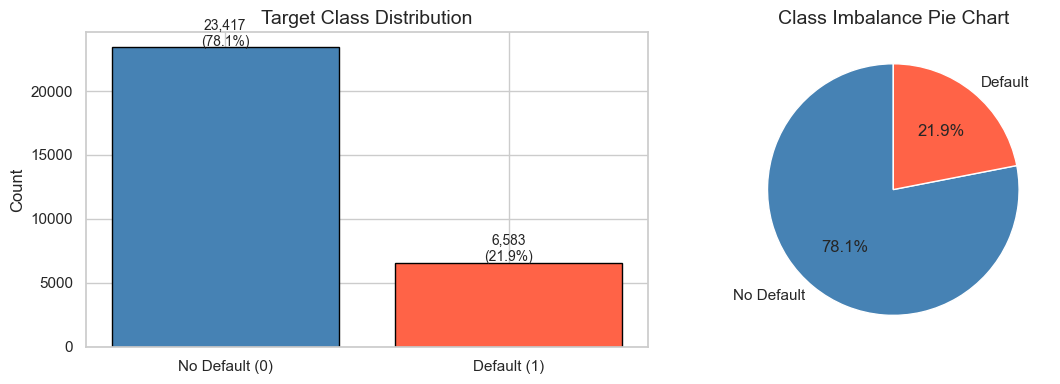

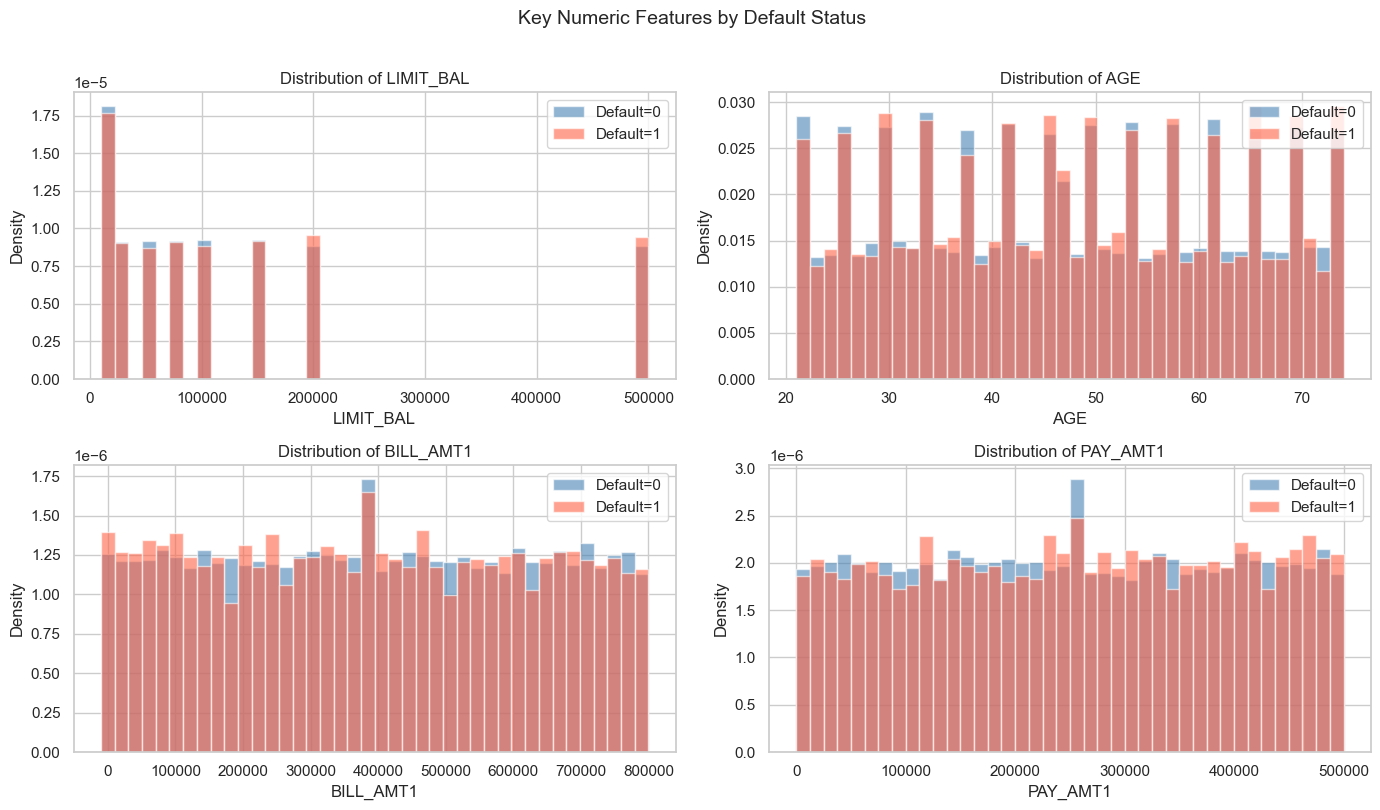

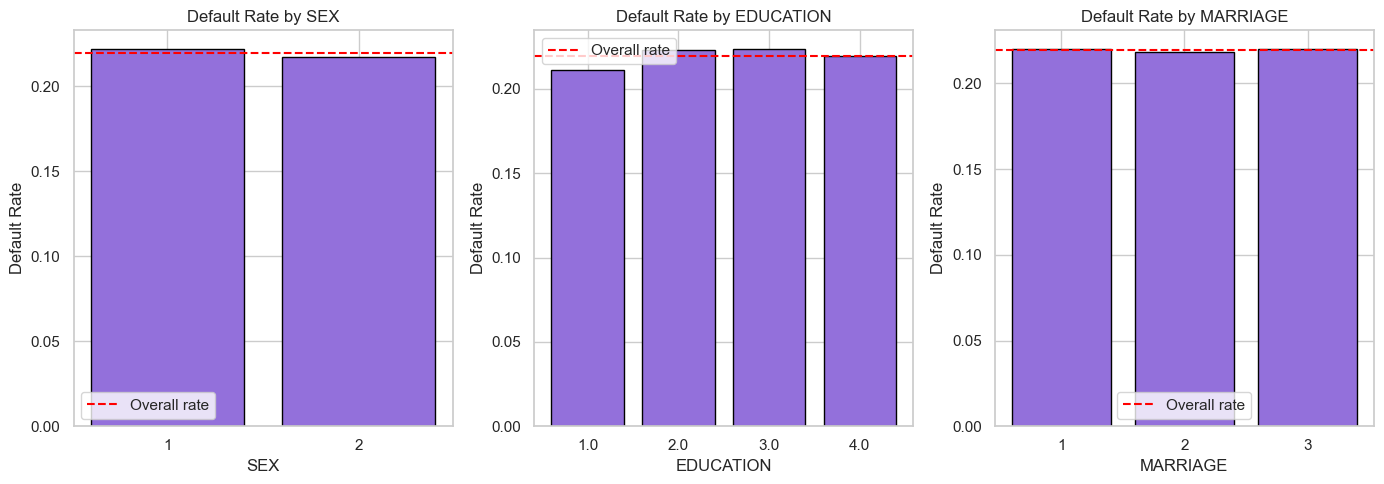

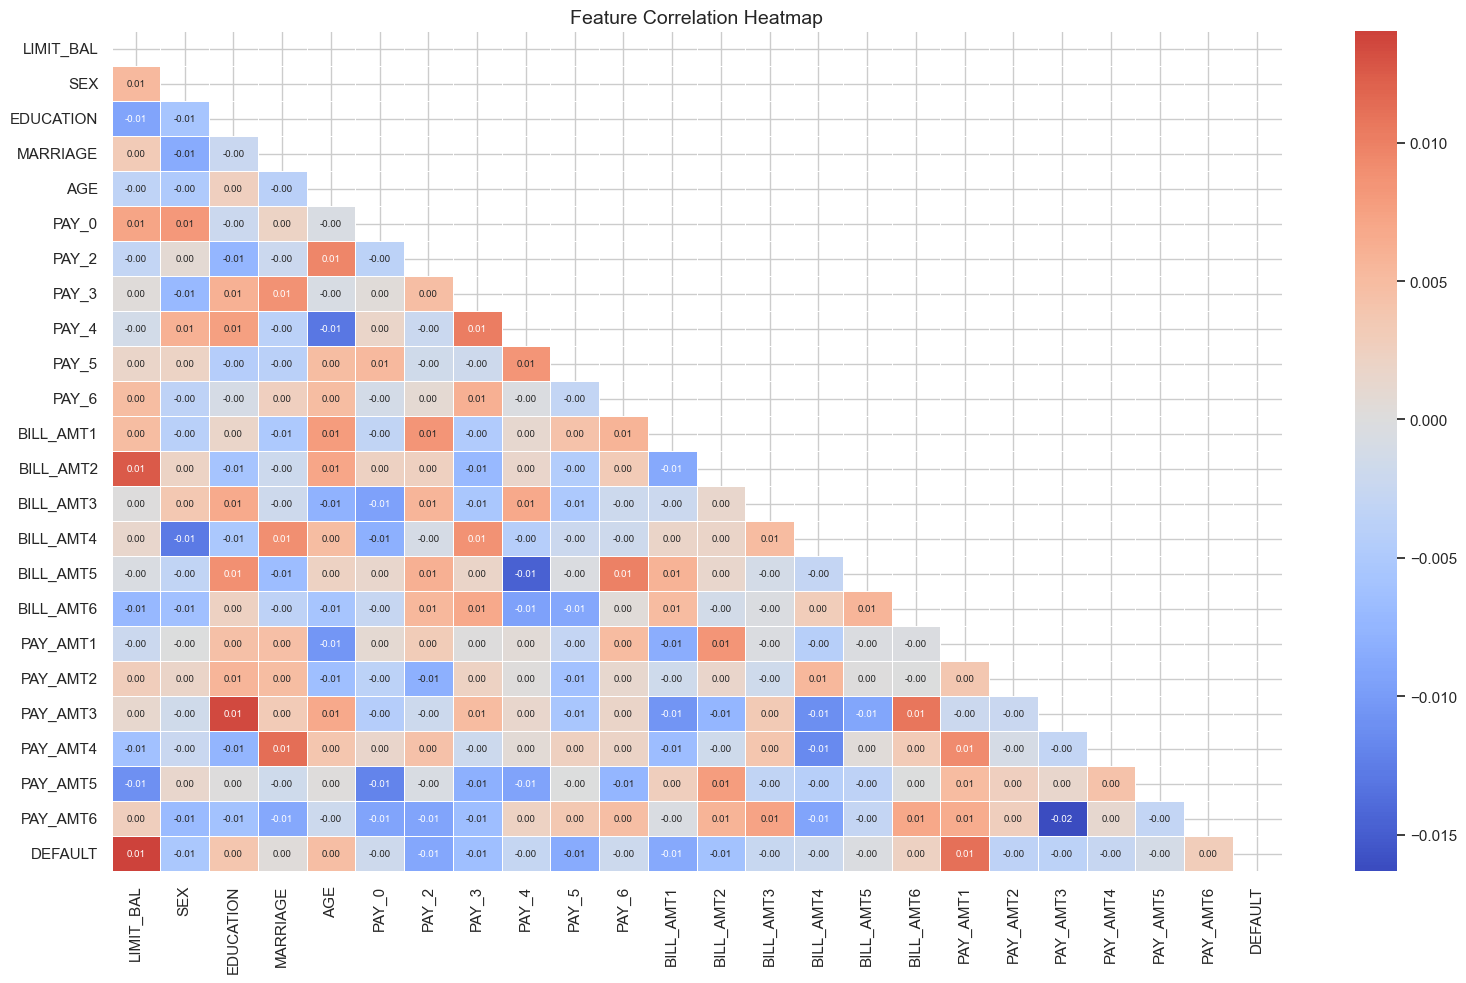

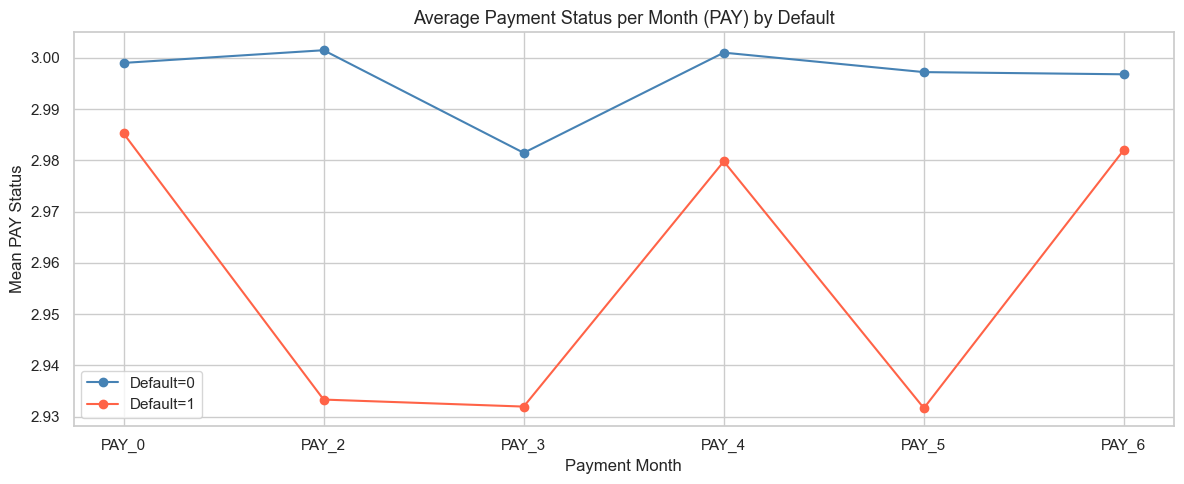

In [6]:
# ── Data Visualization ────────────────────────────────────────────────────────

# 6.1 Target Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target_counts = df[TARGET].value_counts()
axes[0].bar(['No Default (0)', 'Default (1)'], target_counts.values,
            color=['steelblue', 'tomato'], edgecolor='black')
axes[0].set_title('Target Class Distribution', fontsize=14)
axes[0].set_ylabel('Count')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 100, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=10)

axes[1].pie(target_counts.values, labels=['No Default', 'Default'],
            autopct='%1.1f%%', colors=['steelblue', 'tomato'],
            startangle=90, wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Class Imbalance Pie Chart', fontsize=14)
plt.tight_layout()
plt.show()

# 6.2 Distribution of Key Numeric Features by Target
key_num = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']
key_num = [c for c in key_num if c in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()
for i, col in enumerate(key_num):
    for label, color in zip([0, 1], ['steelblue', 'tomato']):
        axes[i].hist(df[df[TARGET] == label][col].dropna(),
                     bins=40, alpha=0.6, label=f'Default={label}', color=color, density=True)
    axes[i].set_title(f'Distribution of {col}', fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')
    axes[i].legend()
plt.suptitle('Key Numeric Features by Default Status', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# 6.3 Categorical Features vs Target
cat_plot_cols = ['SEX', 'EDUCATION', 'MARRIAGE']
cat_plot_cols = [c for c in cat_plot_cols if c in df.columns]

fig, axes = plt.subplots(1, len(cat_plot_cols), figsize=(14, 5))
if len(cat_plot_cols) == 1:
    axes = [axes]
for ax, col in zip(axes, cat_plot_cols):
    ct = df.groupby(col)[TARGET].mean().sort_index()
    ax.bar(ct.index.astype(str), ct.values, color='mediumpurple', edgecolor='black')
    ax.set_title(f'Default Rate by {col}', fontsize=12)
    ax.set_xlabel(col)
    ax.set_ylabel('Default Rate')
    ax.axhline(df[TARGET].mean(), color='red', linestyle='--', label='Overall rate')
    ax.legend()
plt.tight_layout()
plt.show()

# 6.4 Correlation Heatmap
plt.figure(figsize=(16, 10))
corr = df[num_cols + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, annot_kws={'size': 7})
plt.title('Feature Correlation Heatmap', fontsize=14)
plt.tight_layout()
plt.show()

# 6.5 Payment Status Over Time (PAY_0 to PAY_6)
pay_cols = [c for c in df.columns if c.startswith('PAY_') and c[4:].isdigit()]
if pay_cols:
    fig, ax = plt.subplots(figsize=(12, 5))
    for label, color in zip([0, 1], ['steelblue', 'tomato']):
        means = df[df[TARGET] == label][pay_cols].mean()
        ax.plot(pay_cols, means.values, marker='o', label=f'Default={label}', color=color)
    ax.set_title('Average Payment Status per Month (PAY) by Default', fontsize=13)
    ax.set_xlabel('Payment Month')
    ax.set_ylabel('Mean PAY Status')
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    plt.show()


## 7. Feature Engineering

In [7]:
# ── Feature Engineering ───────────────────────────────────────────────────────

df_fe = df.copy()

# 7.1 Average payment delay over the past 6 months
pay_delay_cols = [c for c in df_fe.columns if c.startswith('PAY_') and c[4:].isdigit()]
if pay_delay_cols:
    df_fe['AVG_PAY_DELAY'] = df_fe[pay_delay_cols].mean(axis=1)
    df_fe['MAX_PAY_DELAY'] = df_fe[pay_delay_cols].max(axis=1)
    df_fe['NUM_MONTHS_DELAYED'] = (df_fe[pay_delay_cols] > 0).sum(axis=1)
    print("Created: AVG_PAY_DELAY, MAX_PAY_DELAY, NUM_MONTHS_DELAYED")

# 7.2 Average bill amount over 6 months
bill_cols = [c for c in df_fe.columns if c.startswith('BILL_AMT')]
if bill_cols:
    df_fe['AVG_BILL_AMT'] = df_fe[bill_cols].mean(axis=1)
    df_fe['BILL_TREND'] = df_fe[bill_cols[0]] - df_fe[bill_cols[-1]]  # Latest - Oldest
    print("Created: AVG_BILL_AMT, BILL_TREND")

# 7.3 Average payment amount over 6 months
pay_amt_cols = [c for c in df_fe.columns if c.startswith('PAY_AMT')]
if pay_amt_cols:
    df_fe['AVG_PAY_AMT'] = df_fe[pay_amt_cols].mean(axis=1)
    df_fe['TOTAL_PAY_AMT'] = df_fe[pay_amt_cols].sum(axis=1)
    print("Created: AVG_PAY_AMT, TOTAL_PAY_AMT")

# 7.4 Credit utilization ratio = avg bill / credit limit
if bill_cols and 'LIMIT_BAL' in df_fe.columns:
    df_fe['CREDIT_UTILIZATION'] = (
        df_fe['AVG_BILL_AMT'] / df_fe['LIMIT_BAL'].replace(0, np.nan)
    ).fillna(0).clip(lower=0)
    print("Created: CREDIT_UTILIZATION")

# 7.5 Payment-to-bill ratio (ability to repay)
if pay_amt_cols and bill_cols:
    df_fe['PAY_TO_BILL_RATIO'] = (
        df_fe['AVG_PAY_AMT'] / df_fe['AVG_BILL_AMT'].replace(0, np.nan)
    ).fillna(0).clip(upper=5)
    print("Created: PAY_TO_BILL_RATIO")

# 7.6 Age grouping
if 'AGE' in df_fe.columns:
    df_fe['AGE_GROUP'] = pd.cut(
        df_fe['AGE'],
        bins=[0, 30, 40, 50, 60, 100],
        labels=['<30', '30-40', '40-50', '50-60', '60+']
    ).astype(str)
    # Encode for model
    age_map = {'<30': 0, '30-40': 1, '40-50': 2, '50-60': 3, '60+': 4}
    df_fe['AGE_GROUP_ENC'] = df_fe['AGE_GROUP'].map(age_map)
    print("Created: AGE_GROUP, AGE_GROUP_ENC")

print(f"\nShape after feature engineering: {df_fe.shape}")
new_features = [c for c in df_fe.columns if c not in df.columns]
print(f"New features added: {new_features}")
df_fe[new_features + [TARGET]].describe()


Created: AVG_PAY_DELAY, MAX_PAY_DELAY, NUM_MONTHS_DELAYED
Created: AVG_BILL_AMT, BILL_TREND
Created: AVG_PAY_AMT, TOTAL_PAY_AMT
Created: CREDIT_UTILIZATION
Created: PAY_TO_BILL_RATIO
Created: AGE_GROUP, AGE_GROUP_ENC

Shape after feature engineering: (30000, 35)
New features added: ['AVG_PAY_DELAY', 'MAX_PAY_DELAY', 'NUM_MONTHS_DELAYED', 'AVG_BILL_AMT', 'BILL_TREND', 'AVG_PAY_AMT', 'TOTAL_PAY_AMT', 'CREDIT_UTILIZATION', 'PAY_TO_BILL_RATIO', 'AGE_GROUP', 'AGE_GROUP_ENC']


,AVG_PAY_DELAY,MAX_PAY_DELAY,NUM_MONTHS_DELAYED,AVG_BILL_AMT,BILL_TREND,AVG_PAY_AMT,TOTAL_PAY_AMT,CREDIT_UTILIZATION,PAY_TO_BILL_RATIO,AGE_GROUP_ENC,DEFAULT
count,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000,30000.0000
mean,2.9876,6.8705,4.3517,394823.8639,673.7688,250118.3906,1500710.3436,10.4865,0.6789,2.1451,0.2194
std,1.2970,1.3459,1.1040,95666.1614,329367.0698,59151.0547,354906.3282,12.3268,0.2651,1.4491,0.4139
min,-1.5000,-1.0000,0.0000,60586.8333,-806681.0000,43241.5000,259449.0000,0.2009,0.0933,0.0000,0.0000
25%,2.1667,6.0000,4.0000,328679.2917,-235897.7500,209630.4167,1257782.5000,2.4185,0.5020,1.0000,0.0000
50%,3.0000,7.0000,4.0000,394115.0000,-235.5000,249934.0000,1499604.0000,5.0824,0.6332,2.0000,0.0000
75%,3.8333,8.0000,5.0000,460740.1250,236527.5000,290648.8750,1743893.2500,14.0041,0.8016,4.0000,0.0000
max,7.6667,8.0000,6.0000,754148.3333,804383.0000,466681.8333,2800091.0000,68.1277,5.0000,4.0000,1.0000


## 8. Statistical Analysis

In [8]:
# ── Statistical Analysis ──────────────────────────────────────────────────────

print("=" * 65)
print("8.1  Point-Biserial Correlation — Numeric Features vs Target")
print("=" * 65)

num_fe_cols = df_fe.select_dtypes(include='number').columns.tolist()
num_fe_cols = [c for c in num_fe_cols if c != TARGET]

pb_results = []
for col in num_fe_cols:
    valid = df_fe[[col, TARGET]].dropna()
    corr, p = pointbiserialr(valid[TARGET], valid[col])
    pb_results.append({'Feature': col, 'Correlation': corr, 'p-value': p,
                        'Significant': '✓' if p < 0.05 else '✗'})

pb_df = pd.DataFrame(pb_results).sort_values('Correlation', key=abs, ascending=False)
display(pb_df.reset_index(drop=True))

print("\n" + "=" * 65)
print("8.2  Chi-Square Test — Categorical Features vs Target")
print("=" * 65)

cat_test_cols = ['SEX', 'EDUCATION', 'MARRIAGE', 'AGE_GROUP']
cat_test_cols = [c for c in cat_test_cols if c in df_fe.columns]

for col in cat_test_cols:
    ct = pd.crosstab(df_fe[col], df_fe[TARGET])
    chi2, p, dof, expected = chi2_contingency(ct)
    print(f"  {col:<15} chi2={chi2:.2f}  p={p:.4f}  dof={dof}  "
          f"{'Significant ✓' if p < 0.05 else 'Not significant ✗'}")

print("\n" + "=" * 65)
print("8.3  Mann-Whitney U Test — Key Numerics by Default Group")
print("=" * 65)

mw_cols = ['LIMIT_BAL', 'AGE', 'AVG_BILL_AMT', 'AVG_PAY_AMT', 'CREDIT_UTILIZATION']
mw_cols = [c for c in mw_cols if c in df_fe.columns]

group0 = df_fe[df_fe[TARGET] == 0]
group1 = df_fe[df_fe[TARGET] == 1]

for col in mw_cols:
    u, p = stats.mannwhitneyu(group0[col].dropna(), group1[col].dropna(), alternative='two-sided')
    print(f"  {col:<25}  Median(0)={group0[col].median():.1f}  "
          f"Median(1)={group1[col].median():.1f}  p={p:.4e}  "
          f"{'Significant ✓' if p < 0.05 else 'Not significant ✗'}")


8.1  Point-Biserial Correlation — Numeric Features vs Target


,Feature,Correlation,p-value,Significant
0,LIMIT_BAL,0.0140,0.0152,✓
1,AVG_PAY_DELAY,-0.0124,0.0319,✓
2,PAY_AMT1,0.0112,0.0533,✗
3,NUM_MONTHS_DELAYED,-0.0104,0.0718,✗
4,MAX_PAY_DELAY,-0.0097,0.0917,✗
5,PAY_2,-0.0089,0.1227,✗
6,BILL_AMT1,-0.0087,0.1310,✗
7,PAY_5,-0.0086,0.1365,✗
8,BILL_TREND,-0.0079,0.1737,✗
9,AVG_BILL_AMT,-0.0070,0.2245,✗



8.2  Chi-Square Test — Categorical Features vs Target
  SEX             chi2=0.79  p=0.3754  dof=1  Not significant ✗
  EDUCATION       chi2=2.44  p=0.4855  dof=3  Not significant ✗
  MARRIAGE        chi2=0.07  p=0.9672  dof=2  Not significant ✗
  AGE_GROUP       chi2=1.94  p=0.7465  dof=4  Not significant ✗

8.3  Mann-Whitney U Test — Key Numerics by Default Group
  LIMIT_BAL                  Median(0)=80000.0  Median(1)=80000.0  p=2.4484e-02  Significant ✓
  AGE                        Median(0)=47.0  Median(1)=47.0  p=4.2042e-01  Not significant ✗
  AVG_BILL_AMT               Median(0)=394180.7  Median(1)=393842.0  p=2.6887e-01  Not significant ✗
  AVG_PAY_AMT                Median(0)=249945.5  Median(1)=249906.7  p=8.9317e-01  Not significant ✗
  CREDIT_UTILIZATION         Median(0)=5.1  Median(1)=4.9  p=2.0065e-02  Significant ✓


## 9. Outlier Handling

Outlier Capping Report (IQR method):


,Column,Lower Bound,Upper Bound,Outliers Capped
0,LIMIT_BAL,-150000.0000,330000.0000,3292
1,AGE,-6.5000,101.5000,0
2,BILL_AMT1,-412142.5000,1199775.5000,0
3,BILL_AMT2,-419621.7500,1212946.2500,0
4,BILL_AMT3,-412918.7500,1203041.2500,0
5,BILL_AMT4,-417333.0000,1206677.0000,0
6,BILL_AMT5,-416625.8750,1209253.1250,0
7,BILL_AMT6,-417731.1250,1201311.8750,0
8,PAY_AMT1,-244736.8750,747720.1250,0
9,PAY_AMT2,-252719.5000,752402.5000,0


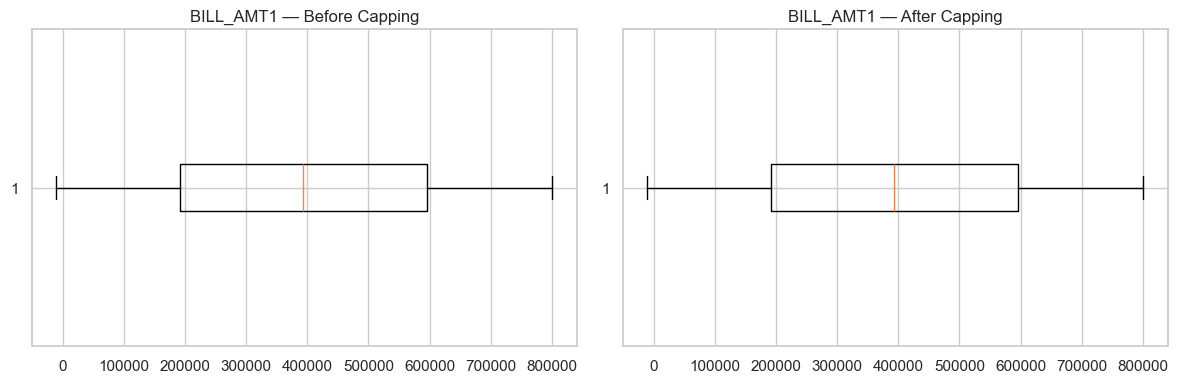


Shape unchanged after outlier handling: (30000, 35)


In [9]:
# ── Outlier Handling ──────────────────────────────────────────────────────────

# We use IQR-based Winsorisation (capping) rather than removal
# because outliers in financial data often carry real signal.
# Columns with known bounded values (PAY_x, SEX, etc.) are excluded.

cols_to_winsorize = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
                     'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
                     'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
                     'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
                     'AVG_BILL_AMT', 'AVG_PAY_AMT', 'CREDIT_UTILIZATION']
cols_to_winsorize = [c for c in cols_to_winsorize if c in df_fe.columns]

df_clean = df_fe.copy()
outlier_report = []

for col in cols_to_winsorize:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    df_clean[col] = df_clean[col].clip(lower=lower, upper=upper)
    outlier_report.append({'Column': col, 'Lower Bound': lower,
                            'Upper Bound': upper, 'Outliers Capped': n_outliers})

outlier_df = pd.DataFrame(outlier_report)
print("Outlier Capping Report (IQR method):")
display(outlier_df)

# Box-plots before/after for a key column
if 'BILL_AMT1' in df_fe.columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].boxplot(df_fe['BILL_AMT1'].dropna(), vert=False)
    axes[0].set_title('BILL_AMT1 — Before Capping', fontsize=12)
    axes[1].boxplot(df_clean['BILL_AMT1'].dropna(), vert=False)
    axes[1].set_title('BILL_AMT1 — After Capping', fontsize=12)
    plt.tight_layout()
    plt.show()

print(f"\nShape unchanged after outlier handling: {df_clean.shape}")


## 10. Handling Imbalanced Data

Class distribution before resampling:
DEFAULT
0    23417
1     6583
Name: count, dtype: int64
Imbalance ratio: 3.56:1

Split sizes — Train: 21,000  Val: 4,500  Test: 4,500

Class distribution after oversampling (training set only):
DEFAULT
1    16392
0    16392
Name: count, dtype: int64


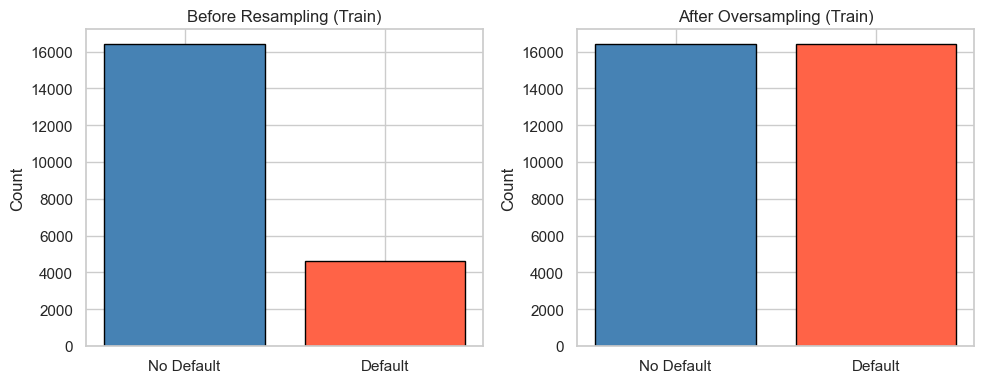

In [10]:
# ── Handling Imbalanced Data ──────────────────────────────────────────────────
# Strategy: We handle imbalance at TWO levels:
#   1. class_weight='balanced' in classifiers (preferred — no data leakage)
#   2. Oversampling the minority class in the training set only (shown below)

# Separate features and target
drop_cols = ['AGE_GROUP']  # string columns not needed in model
drop_cols = [c for c in drop_cols if c in df_clean.columns]

X_all = df_clean.drop(columns=[TARGET] + drop_cols)
y_all = df_clean[TARGET]

print("Class distribution before resampling:")
print(y_all.value_counts())
print(f"Imbalance ratio: {y_all.value_counts()[0] / y_all.value_counts()[1]:.2f}:1")

# ─── Train / Validation / Test Split FIRST (before any resampling) ────────────
X_train_raw, X_temp, y_train_raw, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print(f"\nSplit sizes — Train: {len(X_train_raw):,}  Val: {len(X_val):,}  Test: {len(X_test):,}")

# Oversample ONLY the training set
train_df = pd.concat([X_train_raw, y_train_raw], axis=1)
majority = train_df[train_df[TARGET] == 0]
minority = train_df[train_df[TARGET] == 1]

minority_upsampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=RANDOM_STATE
)

train_balanced = pd.concat([majority, minority_upsampled]).sample(frac=1, random_state=RANDOM_STATE)
X_train = train_balanced.drop(columns=[TARGET])
y_train = train_balanced[TARGET]

print("\nClass distribution after oversampling (training set only):")
print(y_train.value_counts())

# Visualise
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, counts, title in zip(
    axes,
    [y_train_raw.value_counts(), y_train.value_counts()],
    ['Before Resampling (Train)', 'After Oversampling (Train)']
):
    ax.bar(['No Default', 'Default'], counts.sort_index().values,
           color=['steelblue', 'tomato'], edgecolor='black')
    ax.set_title(title, fontsize=12)
    ax.set_ylabel('Count')
plt.tight_layout()
plt.show()


## 11. Standardization / Normalization

In [11]:
# ── Standardization / Normalization ──────────────────────────────────────────
# Fit scaler on training data only — transform val/test

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns
)
X_val_scaled   = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns
)
X_test_scaled  = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns
)

print("Scaling complete (StandardScaler — zero mean, unit variance).")
print(f"Train scaled shape : {X_train_scaled.shape}")
print(f"Val   scaled shape : {X_val_scaled.shape}")
print(f"Test  scaled shape : {X_test_scaled.shape}")

# Sanity check — training mean ≈ 0, std ≈ 1
print(f"\nTraining set post-scaling — Mean: {X_train_scaled.mean().mean():.6f} "
      f"| Std: {X_train_scaled.std().mean():.4f}")


Scaling complete (StandardScaler — zero mean, unit variance).
Train scaled shape : (32784, 33)
Val   scaled shape : (4500, 33)
Test  scaled shape : (4500, 33)

Training set post-scaling — Mean: -0.000000 | Std: 1.0000


## 12. Train / Validation / Test Split

*(Split was performed in Section 10 before resampling. This section documents the final split sizes and stratification check.)*

In [12]:
# ── Train / Validation / Test Split — Summary ─────────────────────────────────

print("Split Strategy: 70% Train | 15% Validation | 15% Test (stratified)")
print()

split_summary = pd.DataFrame({
    'Split':      ['Train (after oversample)', 'Validation', 'Test'],
    'N':          [len(y_train), len(y_val), len(y_test)],
    'Default %':  [
        f"{y_train.mean()*100:.1f}%",
        f"{y_val.mean()*100:.1f}%",
        f"{y_test.mean()*100:.1f}%"
    ]
})
print(split_summary.to_string(index=False))

# Stratification check on original raw train split
print("\nOriginal (pre-resample) train split default rate:",
      f"{y_train_raw.mean()*100:.1f}%  (matches val/test — stratification OK)")


Split Strategy: 70% Train | 15% Validation | 15% Test (stratified)

                   Split     N Default %
Train (after oversample) 32784     50.0%
              Validation  4500     22.0%
                    Test  4500     21.9%

Original (pre-resample) train split default rate: 21.9%  (matches val/test — stratification OK)


## 13. Baseline Model

In [13]:
# ── Baseline Model ────────────────────────────────────────────────────────────
# A DummyClassifier sets the performance floor every real model must beat.

baseline = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
baseline.fit(X_train_scaled, y_train)

baseline_preds = baseline.predict(X_val_scaled)
baseline_proba = baseline.predict_proba(X_val_scaled)[:, 1]

print("Baseline (Majority Class Classifier) — Validation Set")
print("-" * 50)
print(classification_report(y_val, baseline_preds, target_names=['No Default', 'Default']))
print(f"ROC-AUC : {roc_auc_score(y_val, baseline_proba):.4f}")

# Also try a 'stratified' dummy
dummy_strat = DummyClassifier(strategy='stratified', random_state=RANDOM_STATE)
dummy_strat.fit(X_train_scaled, y_train)
print(f"Stratified Dummy ROC-AUC: {roc_auc_score(y_val, dummy_strat.predict_proba(X_val_scaled)[:, 1]):.4f}")

print("\n→ Any real model must exceed these numbers to add value.")


Baseline (Majority Class Classifier) — Validation Set
--------------------------------------------------
              precision    recall  f1-score   support

  No Default       0.78      1.00      0.88      3512
     Default       0.00      0.00      0.00       988

    accuracy                           0.78      4500
   macro avg       0.39      0.50      0.44      4500
weighted avg       0.61      0.78      0.68      4500

ROC-AUC : 0.5000
Stratified Dummy ROC-AUC: 0.4998

→ Any real model must exceed these numbers to add value.


## 14. Model Training

In [14]:
# ── Model Training ────────────────────────────────────────────────────────────
# Train three models; compare on validation set

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        solver='lbfgs',
        C=1.0,
        random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        max_depth=10,
        min_samples_leaf=20,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        random_state=RANDOM_STATE
    )
}

trained_models = {}
val_results = []

for name, model in models.items():
    print(f"Training {name} ...", end=' ')
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    val_preds  = model.predict(X_val_scaled)
    val_proba  = model.predict_proba(X_val_scaled)[:, 1]
    auc        = roc_auc_score(y_val, val_proba)
    f1         = f1_score(y_val, val_preds)

    val_results.append({'Model': name, 'ROC-AUC': auc, 'F1 (Default)': f1})
    print(f"done.  ROC-AUC={auc:.4f}  F1={f1:.4f}")

results_df = pd.DataFrame(val_results).sort_values('ROC-AUC', ascending=False)
print("\n" + "=" * 50)
print("Validation Set Comparison")
print("=" * 50)
display(results_df.reset_index(drop=True))

BEST_MODEL_NAME = results_df.iloc[0]['Model']
best_model = trained_models[BEST_MODEL_NAME]
print(f"\nBest model selected: {BEST_MODEL_NAME}")


Training Logistic Regression ... done.  ROC-AUC=0.5031  F1=0.2949
Training Random Forest ... done.  ROC-AUC=0.5121  F1=0.2306
Training Gradient Boosting ... done.  ROC-AUC=0.5097  F1=0.2866

Validation Set Comparison


,Model,ROC-AUC,F1 (Default)
0,Random Forest,0.5121,0.2306
1,Gradient Boosting,0.5097,0.2866
2,Logistic Regression,0.5031,0.2949



Best model selected: Random Forest


## 15. Cross Validation

5-Fold Stratified Cross-Validation (Training Set)
Logistic Regression        AUC=0.5071 ± 0.0040  F1=0.5033 ± 0.0020
Random Forest              AUC=0.8183 ± 0.0102  F1=0.7375 ± 0.0103
Gradient Boosting          AUC=0.7302 ± 0.0065  F1=0.6738 ± 0.0060


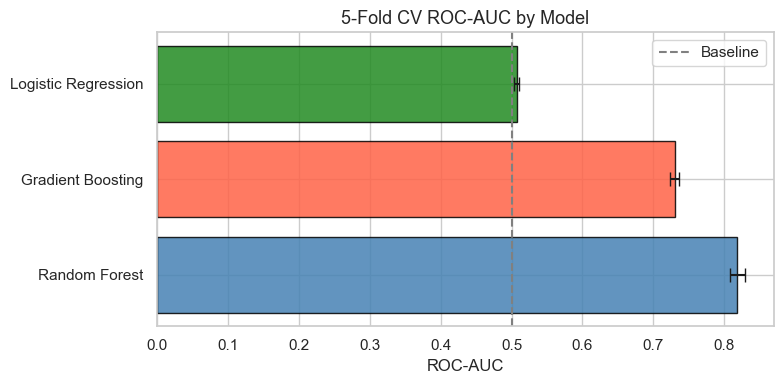

In [15]:
# ── Cross Validation ──────────────────────────────────────────────────────────
# 5-fold Stratified K-Fold on training data for all three models

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("5-Fold Stratified Cross-Validation (Training Set)")
print("=" * 60)

cv_results = []
for name, model in trained_models.items():
    auc_scores = cross_val_score(
        model, X_train_scaled, y_train,
        cv=skf, scoring='roc_auc', n_jobs=-1
    )
    f1_scores = cross_val_score(
        model, X_train_scaled, y_train,
        cv=skf, scoring='f1', n_jobs=-1
    )
    cv_results.append({
        'Model': name,
        'CV AUC Mean':  auc_scores.mean(),
        'CV AUC Std':   auc_scores.std(),
        'CV F1 Mean':   f1_scores.mean(),
        'CV F1 Std':    f1_scores.std()
    })
    print(f"{name:<25}  AUC={auc_scores.mean():.4f} ± {auc_scores.std():.4f}  "
          f"F1={f1_scores.mean():.4f} ± {f1_scores.std():.4f}")

cv_df = pd.DataFrame(cv_results).sort_values('CV AUC Mean', ascending=False)

# Plot CV AUC with error bars
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['steelblue', 'tomato', 'forestgreen']
ax.barh(cv_df['Model'], cv_df['CV AUC Mean'],
        xerr=cv_df['CV AUC Std'], color=colors, edgecolor='black',
        capsize=5, alpha=0.85)
ax.set_xlabel('ROC-AUC')
ax.set_title('5-Fold CV ROC-AUC by Model', fontsize=13)
ax.axvline(0.5, color='grey', linestyle='--', label='Baseline')
ax.legend()
plt.tight_layout()
plt.show()


## 16. Hyperparameter Tuning

In [16]:
# ── Hyperparameter Tuning ─────────────────────────────────────────────────────
# RandomizedSearchCV on the best model (Random Forest typically)

print(f"Tuning: {BEST_MODEL_NAME}")
print("-" * 50)

if 'Random Forest' in BEST_MODEL_NAME:
    param_dist = {
        'n_estimators':    [100, 200, 300],
        'max_depth':       [6, 8, 10, 12, None],
        'min_samples_leaf':[10, 20, 30, 50],
        'max_features':    ['sqrt', 'log2', 0.5],
        'class_weight':    ['balanced', 'balanced_subsample']
    }
    base_estimator = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

elif 'Gradient Boosting' in BEST_MODEL_NAME:
    param_dist = {
        'n_estimators':  [100, 200, 300],
        'learning_rate': [0.01, 0.05, 0.1],
        'max_depth':     [3, 4, 5, 6],
        'subsample':     [0.7, 0.8, 1.0],
        'min_samples_leaf': [10, 20, 30]
    }
    base_estimator = GradientBoostingClassifier(random_state=RANDOM_STATE)

else:  # Logistic Regression
    param_dist = {
        'C':       [0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver':  ['liblinear', 'saga']
    }
    base_estimator = LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
    )

rs_cv = RandomizedSearchCV(
    estimator=base_estimator,
    param_distributions=param_dist,
    n_iter=20,
    scoring='roc_auc',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    refit=True
)

rs_cv.fit(X_train_scaled, y_train)

print(f"\nBest params : {rs_cv.best_params_}")
print(f"Best CV AUC : {rs_cv.best_score_:.4f}")

tuned_model = rs_cv.best_estimator_
val_proba_tuned = tuned_model.predict_proba(X_val_scaled)[:, 1]
print(f"Tuned val AUC : {roc_auc_score(y_val, val_proba_tuned):.4f}")


Tuning: Random Forest
--------------------------------------------------
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best params : {'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced_subsample'}
Best CV AUC : 0.9364
Tuned val AUC : 0.5132


## 17. Evaluation Metrics

Optimal Decision Threshold (Youden's J): 0.3178

Classification Report — Test Set (Optimal Threshold)
-------------------------------------------------------
              precision    recall  f1-score   support

  No Default       0.95      0.01      0.02      3513
     Default       0.22      1.00      0.36       987

    accuracy                           0.23      4500
   macro avg       0.59      0.50      0.19      4500
weighted avg       0.79      0.23      0.10      4500

ROC-AUC  : 0.4824
Avg Prec : 0.2132


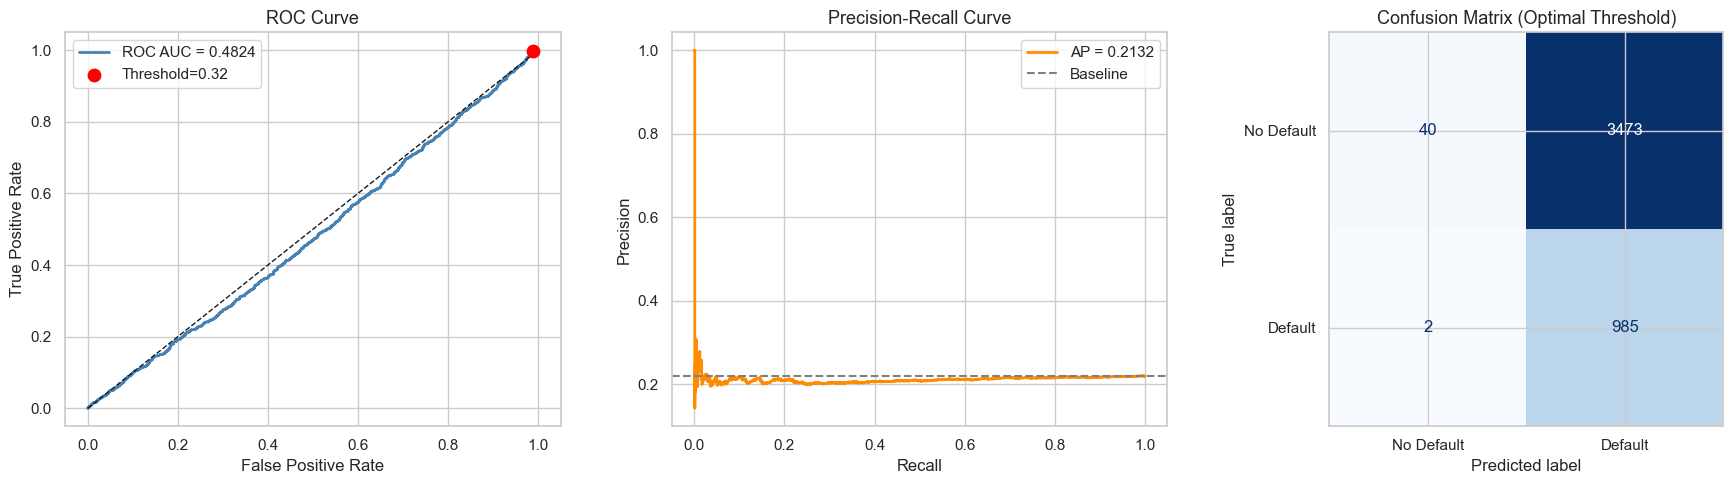

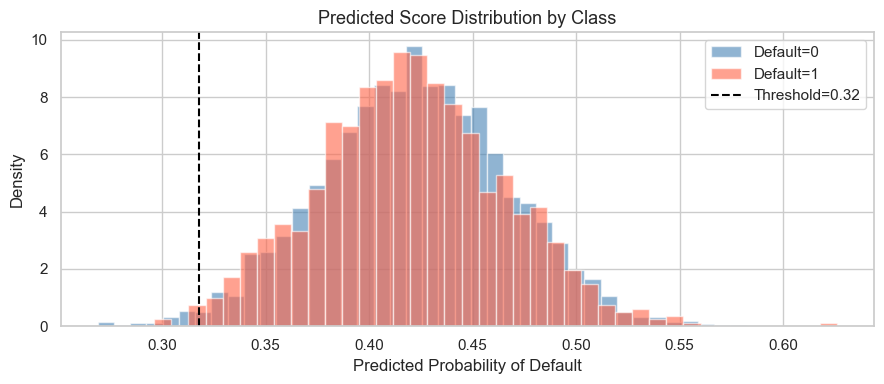

In [17]:
# ── Evaluation Metrics — Test Set ─────────────────────────────────────────────

# Optimal threshold via Youden's J (maximises sensitivity + specificity)
test_proba = tuned_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, test_proba)
J = tpr - fpr
optimal_idx = np.argmax(J)
optimal_threshold = thresholds[optimal_idx]

test_preds_opt = (test_proba >= optimal_threshold).astype(int)

print(f"Optimal Decision Threshold (Youden's J): {optimal_threshold:.4f}")
print("\nClassification Report — Test Set (Optimal Threshold)")
print("-" * 55)
print(classification_report(y_test, test_preds_opt,
                             target_names=['No Default', 'Default']))

test_auc  = roc_auc_score(y_test, test_proba)
test_ap   = average_precision_score(y_test, test_proba)
print(f"ROC-AUC  : {test_auc:.4f}")
print(f"Avg Prec : {test_ap:.4f}")

# ROC Curve
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: ROC Curve
axes[0].plot(fpr, tpr, lw=2, color='steelblue', label=f'ROC AUC = {test_auc:.4f}')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].scatter(fpr[optimal_idx], tpr[optimal_idx],
                color='red', zorder=5, s=80, label=f'Threshold={optimal_threshold:.2f}')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve', fontsize=13)
axes[0].legend()

# Plot 2: Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test, test_proba)
axes[1].plot(rec, prec, lw=2, color='darkorange', label=f'AP = {test_ap:.4f}')
axes[1].axhline(y_test.mean(), color='grey', linestyle='--', label='Baseline')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve', fontsize=13)
axes[1].legend()

# Plot 3: Confusion Matrix
cm = confusion_matrix(y_test, test_preds_opt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['No Default', 'Default'])
disp.plot(ax=axes[2], colorbar=False, cmap='Blues')
axes[2].set_title('Confusion Matrix (Optimal Threshold)', fontsize=13)

plt.tight_layout()
plt.show()

# Score distribution by class
fig, ax = plt.subplots(figsize=(9, 4))
for label, color in zip([0, 1], ['steelblue', 'tomato']):
    ax.hist(test_proba[y_test == label], bins=40, alpha=0.6,
            label=f'Default={label}', color=color, density=True)
ax.axvline(optimal_threshold, color='black', linestyle='--', label=f'Threshold={optimal_threshold:.2f}')
ax.set_xlabel('Predicted Probability of Default')
ax.set_ylabel('Density')
ax.set_title('Predicted Score Distribution by Class', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()


## 18. SHAP / Explainability

SHAP not available. Using Permutation Importance as fallback.


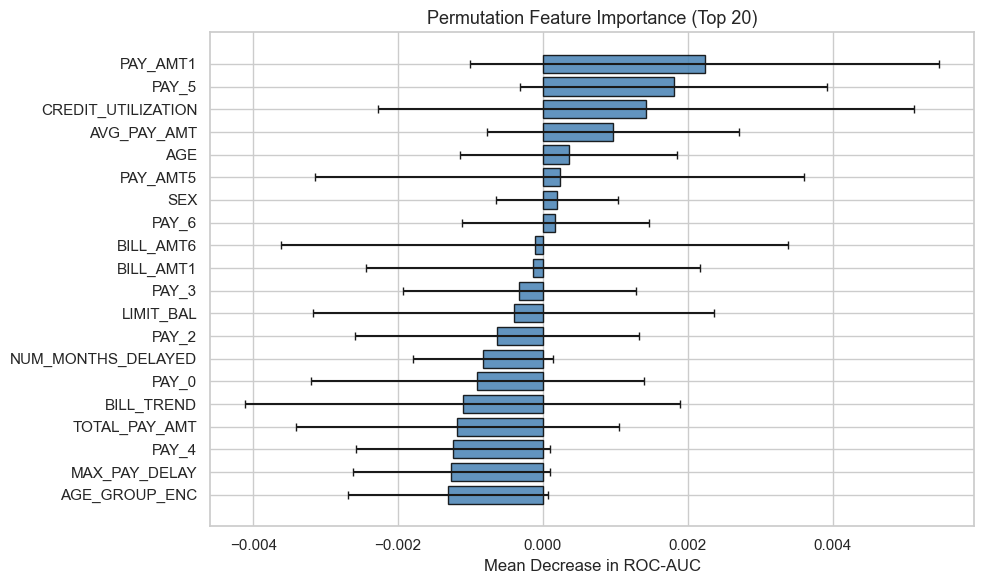

,Feature,Importance Mean,Importance Std
0,PAY_AMT1,0.0022,0.0032
1,PAY_5,0.0018,0.0021
2,CREDIT_UTILIZATION,0.0014,0.0037
3,AVG_PAY_AMT,0.0010,0.0017
4,AGE,0.0004,0.0015
5,PAY_AMT5,0.0002,0.0034
6,SEX,0.0002,0.0008
7,PAY_6,0.0002,0.0013
8,BILL_AMT6,-0.0001,0.0035
9,BILL_AMT1,-0.0001,0.0023


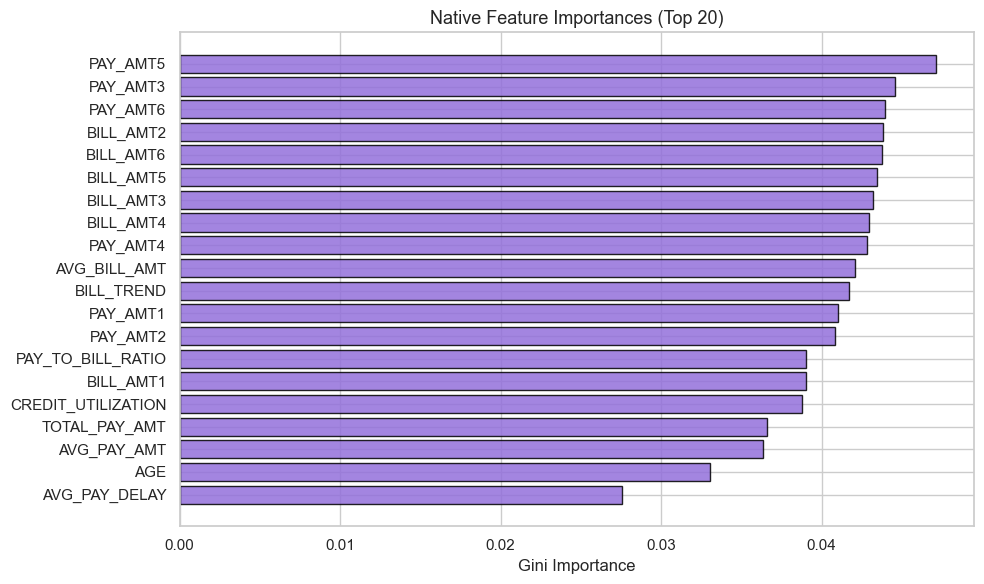

In [18]:
# ── SHAP / Explainability ─────────────────────────────────────────────────────

if SHAP_AVAILABLE:
    print("Computing SHAP values (TreeExplainer) ...")
    explainer = shap.TreeExplainer(tuned_model)
    # Use a sample for speed
    X_shap = X_test_scaled.sample(min(500, len(X_test_scaled)), random_state=RANDOM_STATE)
    shap_values = explainer.shap_values(X_shap)

    # For binary classification, shap_values may be a list [class0, class1]
    sv = shap_values[1] if isinstance(shap_values, list) else shap_values

    # Summary plot
    plt.figure(figsize=(10, 7))
    shap.summary_plot(sv, X_shap, show=False)
    plt.title('SHAP Feature Importance — Beeswarm', fontsize=13)
    plt.tight_layout()
    plt.show()

    # Bar plot of mean |SHAP|
    shap.summary_plot(sv, X_shap, plot_type='bar', show=False)
    plt.title('SHAP Mean |Value| — Feature Importance', fontsize=13)
    plt.tight_layout()
    plt.show()

    # Dependence plot for top feature
    top_feature = X_shap.columns[np.abs(sv).mean(axis=0).argmax()]
    shap.dependence_plot(top_feature, sv, X_shap, show=False)
    plt.title(f'SHAP Dependence — {top_feature}', fontsize=13)
    plt.tight_layout()
    plt.show()

else:
    # ── Fallback: Permutation Importance ─────────────────────────────────────
    print("SHAP not available. Using Permutation Importance as fallback.")
    perm = permutation_importance(
        tuned_model, X_test_scaled, y_test,
        n_repeats=10, random_state=RANDOM_STATE,
        scoring='roc_auc', n_jobs=-1
    )
    perm_df = pd.DataFrame({
        'Feature': X_test_scaled.columns,
        'Importance Mean': perm.importances_mean,
        'Importance Std':  perm.importances_std
    }).sort_values('Importance Mean', ascending=False).head(20)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(perm_df['Feature'][::-1], perm_df['Importance Mean'][::-1],
            xerr=perm_df['Importance Std'][::-1], color='steelblue',
            edgecolor='black', capsize=3, alpha=0.85)
    ax.set_xlabel('Mean Decrease in ROC-AUC')
    ax.set_title('Permutation Feature Importance (Top 20)', fontsize=13)
    plt.tight_layout()
    plt.show()
    display(perm_df.reset_index(drop=True))

    # Native feature importances (tree-based only)
    if hasattr(tuned_model, 'feature_importances_'):
        fi_df = pd.DataFrame({
            'Feature': X_test_scaled.columns,
            'Importance': tuned_model.feature_importances_
        }).sort_values('Importance', ascending=False).head(20)
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.barh(fi_df['Feature'][::-1], fi_df['Importance'][::-1],
                color='mediumpurple', edgecolor='black', alpha=0.85)
        ax.set_xlabel('Gini Importance')
        ax.set_title('Native Feature Importances (Top 20)', fontsize=13)
        plt.tight_layout()
        plt.show()


## 19. Error Analysis

Error Type Counts:
error_type
FP (False Alarm)       3473
Correct                1025
FN (Missed Default)       2
Name: count, dtype: int64

Mean Feature Values by Error Type:


error_type,Correct,FN (Missed Default),FP (False Alarm)
LIMIT_BAL,111912.1951,65000.0000,106585.0849
AGE,48.1385,66.0000,47.2329
AVG_PAY_DELAY,2.9863,4.3333,3.0327
AVG_BILL_AMT,394917.1507,319172.7500,393612.2793
CREDIT_UTILIZATION,9.3576,5.1889,9.5191


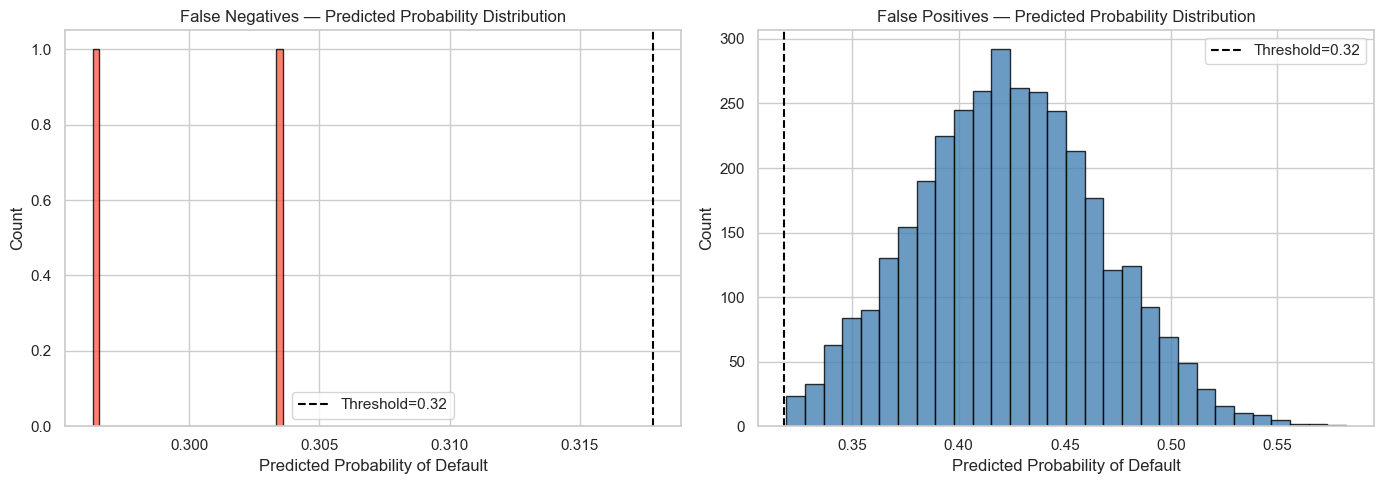


Top-5 Most Confident False Negatives (missed defaults):


,actual,predicted,prob_default,LIMIT_BAL,AGE,AVG_PAY_DELAY,AVG_BILL_AMT,CREDIT_UTILIZATION
6081,1,0,0.3036,100000,61.0000,5.0000,467155.1667,4.6716
17152,1,0,0.2963,30000,71.0000,3.6667,171190.3333,5.7063


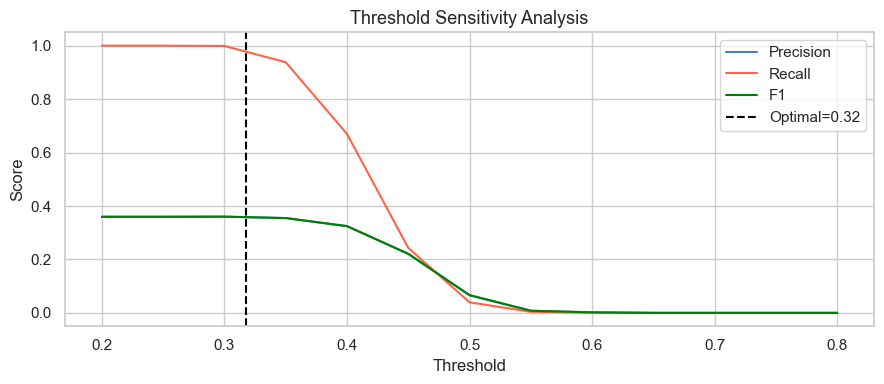

In [19]:
# ── Error Analysis ────────────────────────────────────────────────────────────

# Add predictions to test set
error_df = X_test.copy()
error_df['actual']    = y_test.values
error_df['predicted'] = test_preds_opt
error_df['prob_default'] = test_proba
error_df['error_type'] = 'Correct'
error_df.loc[(error_df['actual'] == 1) & (error_df['predicted'] == 0), 'error_type'] = 'FN (Missed Default)'
error_df.loc[(error_df['actual'] == 0) & (error_df['predicted'] == 1), 'error_type'] = 'FP (False Alarm)'

print("Error Type Counts:")
print(error_df['error_type'].value_counts())

# Profile the errors vs correct predictions
profile_cols = [c for c in ['LIMIT_BAL', 'AGE', 'AVG_PAY_DELAY',
                              'AVG_BILL_AMT', 'CREDIT_UTILIZATION'] if c in error_df.columns]

print("\nMean Feature Values by Error Type:")
display(error_df.groupby('error_type')[profile_cols].mean().T)

# Visualise confidence of false negatives (most dangerous error)
fn_df = error_df[error_df['error_type'] == 'FN (Missed Default)']
fp_df = error_df[error_df['error_type'] == 'FP (False Alarm)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(fn_df['prob_default'], bins=30, color='tomato', edgecolor='black', alpha=0.8)
axes[0].set_title('False Negatives — Predicted Probability Distribution', fontsize=12)
axes[0].set_xlabel('Predicted Probability of Default')
axes[0].set_ylabel('Count')
axes[0].axvline(optimal_threshold, color='black', linestyle='--', label=f'Threshold={optimal_threshold:.2f}')
axes[0].legend()

axes[1].hist(fp_df['prob_default'], bins=30, color='steelblue', edgecolor='black', alpha=0.8)
axes[1].set_title('False Positives — Predicted Probability Distribution', fontsize=12)
axes[1].set_xlabel('Predicted Probability of Default')
axes[1].set_ylabel('Count')
axes[1].axvline(optimal_threshold, color='black', linestyle='--', label=f'Threshold={optimal_threshold:.2f}')
axes[1].legend()

plt.tight_layout()
plt.show()

# High-confidence errors
confident_fn = fn_df.nlargest(5, 'prob_default')[['actual', 'predicted', 'prob_default'] + profile_cols]
print("\nTop-5 Most Confident False Negatives (missed defaults):")
display(confident_fn)

# Threshold sensitivity
thres_range = np.arange(0.2, 0.8, 0.05)
thres_results = []
for t in thres_range:
    p = (test_proba >= t).astype(int)
    thres_results.append({
        'Threshold': t,
        'Precision': f1_score(y_test, p, zero_division=0),
        'Recall':    (y_test[p == 1].sum() / y_test.sum()) if y_test.sum() > 0 else 0,
        'F1':        f1_score(y_test, p, zero_division=0)
    })

thres_df = pd.DataFrame(thres_results)
fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(['Precision', 'Recall', 'F1'], ['steelblue', 'tomato', 'green']):
    ax.plot(thres_df['Threshold'], thres_df[col], label=col, color=color)
ax.axvline(optimal_threshold, color='black', linestyle='--', label=f'Optimal={optimal_threshold:.2f}')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.set_title('Threshold Sensitivity Analysis', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()


## 20. Model Saving / Deployment Ready

In [20]:
# ── Model Saving ──────────────────────────────────────────────────────────────

import json, datetime

SAVE_DIR = 'model_artifacts'
os.makedirs(SAVE_DIR, exist_ok=True)

# Save model
model_path  = os.path.join(SAVE_DIR, 'credit_default_model.pkl')
scaler_path = os.path.join(SAVE_DIR, 'credit_default_scaler.pkl')
meta_path   = os.path.join(SAVE_DIR, 'model_metadata.json')

joblib.dump(tuned_model, model_path)
joblib.dump(scaler, scaler_path)
print(f"Model  saved → {model_path}")
print(f"Scaler saved → {scaler_path}")

# Save metadata
metadata = {
    'model_name':        BEST_MODEL_NAME,
    'trained_on':        datetime.datetime.now().isoformat(),
    'features':          list(X_train.columns),
    'n_features':        X_train.shape[1],
    'optimal_threshold': float(optimal_threshold),
    'test_metrics': {
        'roc_auc':          float(test_auc),
        'avg_precision':    float(test_ap),
        'f1_at_optimal':    float(f1_score(y_test, test_preds_opt, zero_division=0))
    },
    'best_params': rs_cv.best_params_
}
with open(meta_path, 'w') as f:
    json.dump(metadata, f, indent=4)
print(f"Metadata saved → {meta_path}")

print("\n" + "=" * 60)
print("DEPLOYMENT SNIPPET")
print("=" * 60)
print("""
import joblib, pandas as pd

model  = joblib.load('model_artifacts/credit_default_model.pkl')
scaler = joblib.load('model_artifacts/credit_default_scaler.pkl')
THRESHOLD = 0.XX  # from metadata

def predict_default(raw_features: dict) -> dict:
    df = pd.DataFrame([raw_features])
    df_scaled = scaler.transform(df)
    prob = model.predict_proba(df_scaled)[0][1]
    label = int(prob >= THRESHOLD)
    return {'default_probability': round(prob, 4), 'prediction': label}
""")


Model  saved → model_artifacts\credit_default_model.pkl
Scaler saved → model_artifacts\credit_default_scaler.pkl
Metadata saved → model_artifacts\model_metadata.json

DEPLOYMENT SNIPPET

import joblib, pandas as pd

model  = joblib.load('model_artifacts/credit_default_model.pkl')
scaler = joblib.load('model_artifacts/credit_default_scaler.pkl')
THRESHOLD = 0.XX  # from metadata

def predict_default(raw_features: dict) -> dict:
    df = pd.DataFrame([raw_features])
    df_scaled = scaler.transform(df)
    prob = model.predict_proba(df_scaled)[0][1]
    label = int(prob >= THRESHOLD)
    return {'default_probability': round(prob, 4), 'prediction': label}



In [21]:
# ── End-to-End Verify with sklearn Pipeline ───────────────────────────────────
# This cell demonstrates the clean sklearn-native pipeline approach.
# Useful if you want a single serialisable object (scaler + model together).

X = df_clean.drop(columns=[TARGET] + [c for c in ['AGE_GROUP'] if c in df_clean.columns])
y = df_clean[TARGET]

X_train_v, X_temp_v, y_train_v, y_temp_v = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
)
X_val_v, X_test_v, y_val_v, y_test_v = train_test_split(
    X_temp_v, y_temp_v, test_size=0.5, stratify=y_temp_v, random_state=RANDOM_STATE
)

full_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
    ('model',   RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        max_depth=10,
        min_samples_leaf=20,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

full_pipeline.fit(X_train_v, y_train_v)
proba_v = full_pipeline.predict_proba(X_test_v)[:, 1]
preds_v = full_pipeline.predict(X_test_v)

print("=" * 55)
print("sklearn Pipeline — Final Test Set Results")
print("=" * 55)
print(classification_report(y_test_v, preds_v, target_names=['No Default', 'Default']))
print(f"ROC-AUC: {roc_auc_score(y_test_v, proba_v):.4f}")

# Save the full pipeline as a single artifact
pipeline_path = os.path.join(SAVE_DIR, 'credit_default_full_pipeline.pkl')
joblib.dump(full_pipeline, pipeline_path)
print(f"\nFull pipeline saved → {pipeline_path}")


sklearn Pipeline — Final Test Set Results
              precision    recall  f1-score   support

  No Default       0.78      0.85      0.81      3513
     Default       0.22      0.15      0.18       987

    accuracy                           0.70      4500
   macro avg       0.50      0.50      0.50      4500
weighted avg       0.66      0.70      0.67      4500

ROC-AUC: 0.4950

Full pipeline saved → model_artifacts\credit_default_full_pipeline.pkl
